# Predictive Modeling
Time-based split, train Linear Regression / Random Forest / Gradient Boosting, compare RMSE, MAE, R2, save best model.


In [1]:
# Cell 1: setup
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from src.config import *
from src.modeling import *

In [2]:
# Cell 2: load and split
df = load_clean()
X_train, X_test, y_train, y_test = split(df)
print(X_train.shape, X_test.shape)
print(X_train.isna().sum().sum(), "nulls in training features")

(3272, 8) (818, 8)
0 nulls in training features


In [3]:
# Cell 3: train and compare everything (may take a minute or two)
results, fitted = run_experiments(X_train, X_test, y_train, y_test)
results

,model,cv_rmse,cv_rmse_std,test_rmse,test_mae,test_r2
0,Baseline (mean),297.4972,4.4707,302.9522,250.1981,-0.0059
1,Linear Regression,206.2312,2.9079,208.7438,187.8386,0.5224
2,Random Forest,170.4398,3.1874,162.3863,142.9953,0.7110
3,Gradient Boosting,187.1134,4.6588,186.4820,172.5019,0.6188


In [4]:
# Cell 4: choose the best and save the metrics
best_name = select_best(results)
print("Selected model:", best_name)
results.to_csv(METRICS_FILE, index=False)
best_pipe = fitted[best_name]

Selected model: Random Forest


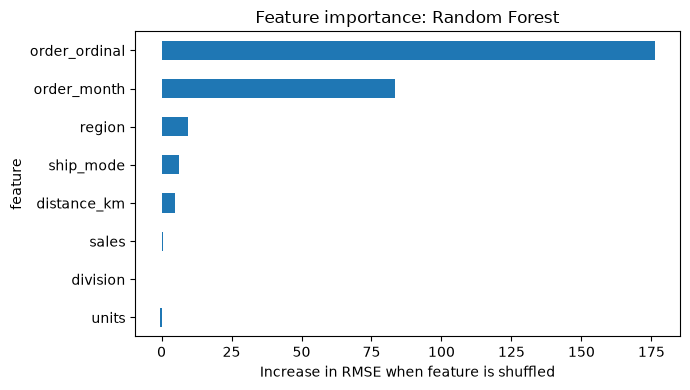

,feature,importance
3,order_ordinal,176.363306
4,order_month,83.531265
6,region,9.518601
5,ship_mode,6.322377
0,distance_km,4.830455
2,sales,0.543422
7,division,0.037753
1,units,-0.590316


In [5]:
# Cell 5: which features matter? (permutation importance on the test set)
imp = permutation_importance(best_pipe, X_test, y_test, n_repeats=5,
                             scoring="neg_root_mean_squared_error",
                             random_state=RANDOM_SEED, n_jobs=1)
imp_df = (pd.DataFrame({"feature": X_test.columns, "importance": imp.importances_mean})
          .sort_values("importance"))
ax = imp_df.plot.barh(x="feature", y="importance", legend=False, figsize=(7, 4))
ax.set_xlabel("Increase in RMSE when feature is shuffled")
ax.set_title(f"Feature importance: {best_name}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance.png", dpi=150)
plt.show()
imp_df.sort_values("importance", ascending=False)

In [6]:
# Cell 6: CRITICAL: does the model respond to distance? (the simulation depends on this)
sample = X_test.sample(min(500, len(X_test)), random_state=RANDOM_SEED)
for km in [200, 800, 1500, 2500]:
    s = sample.copy()
    s["distance_km"] = km
    print(f"distance {km:>5} km -> mean predicted lead time {best_pipe.predict(s).mean():.2f} days")

distance   200 km -> mean predicted lead time 1334.87 days
distance   800 km -> mean predicted lead time 1338.56 days
distance  1500 km -> mean predicted lead time 1342.50 days
distance  2500 km -> mean predicted lead time 1342.52 days


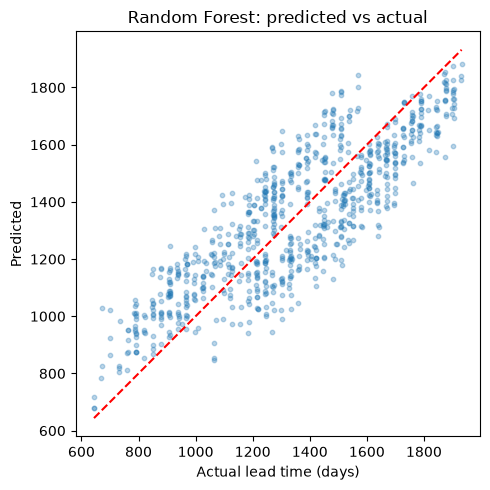

In [7]:
# Cell 7: predicted vs actual plot
pred = best_pipe.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.3, s=10)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual lead time (days)"); plt.ylabel("Predicted")
plt.title(f"{best_name}: predicted vs actual")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pred_vs_actual.png", dpi=150)
plt.show()

In [8]:
# Cell 8: save and verify the saved model reloads and predicts identically
save_model(best_pipe)
reloaded = load_model()
assert np.allclose(reloaded.predict(X_test), best_pipe.predict(X_test))
print("Model saved to", MODEL_FILE)

Model saved to D:\nassau-candy-optimizer\models\best_model.joblib


In [9]:
#check-3
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

d = load_clean()
od = pd.to_datetime(d[COL_ORDER_DATE])
d["order_ordinal"] = (od - od.min()).dt.days
d["order_month"], d["order_dow"], d["order_year"] = od.dt.month, od.dt.dayofweek, od.dt.year
kf = KFold(5, shuffle=True, random_state=RANDOM_SEED)

def cv_rmse(num, cat):
    parts = [("num", StandardScaler(), num)]
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                      max_depth=3, random_state=RANDOM_SEED)
    pipe = Pipeline([("prep", ColumnTransformer(parts)), ("model", model)])
    cv = -cross_val_score(pipe, d[num + cat], d[TARGET], cv=kf,
                          scoring="neg_root_mean_squared_error")
    return round(cv.mean(), 1)

time_f = ["order_ordinal", "order_month", "order_dow"]
log_num, log_cat = ["distance_km", "units", "sales"], ["ship_mode", "region", "division"]

print("Baseline (target std):          ", round(d[TARGET].std(), 1))
print("Order year only:                ", cv_rmse(["order_year"], []))
print("Time features only:             ", cv_rmse(time_f, []))
print("Logistics features only:        ", cv_rmse(log_num, log_cat))
print("Time + logistics:               ", cv_rmse(time_f + log_num, log_cat))
print("Time + logistics + product etc.:", cv_rmse(time_f + log_num, log_cat + ["product", "factory", "state"]))

# Distance effect after controlling for time
lr = LinearRegression().fit(d[["order_ordinal", "distance_km"]], d[TARGET])
print("\nLinear coefficients (days per unit):",
      dict(zip(["order_ordinal", "distance_km"], lr.coef_.round(4))))

Baseline (target std):           298.6
Order year only:                 230.4
Time features only:              183.8
Logistics features only:         298.7
Time + logistics:                187.0
Time + logistics + product etc.: 188.8

Linear coefficients (days per unit): {'order_ordinal': np.float64(0.5541), 'distance_km': np.float64(0.0096)}


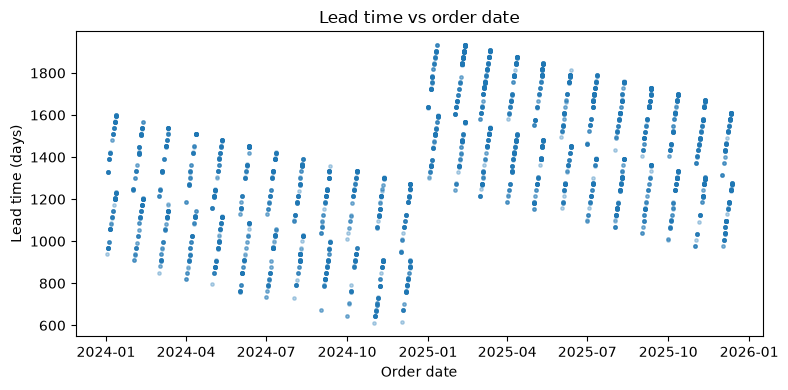

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.scatter(od, d[TARGET], s=6, alpha=0.3)
plt.xlabel("Order date"); plt.ylabel("Lead time (days)")
plt.title("Lead time vs order date")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "leadtime_vs_orderdate.png", dpi=150)
plt.show()

In [11]:
import numpy as np, pandas as pd
from src.config import *
from src.modeling import *

# 1. Files exist and are newer than the data they came from (no stale artifacts)
for f in [CLEAN_FILE, MODEL_FILE, METRICS_FILE,
          FIGURES_DIR / "feature_importance.png", FIGURES_DIR / "pred_vs_actual.png"]:
    assert f.exists(), f"Missing: {f.name}"
assert MODEL_FILE.stat().st_mtime > CLEAN_FILE.stat().st_mtime, "Model is older than clean.csv: retrain"
assert METRICS_FILE.stat().st_mtime > CLEAN_FILE.stat().st_mtime, "Metrics are older than clean.csv: rerun"

# 2. Data has every model column, with no nulls
df = load_clean()
need = FEATURES + [TARGET]
assert not [c for c in need if c not in df.columns], "Missing columns in clean.csv"
assert not df[need].isna().any().any(), "Nulls in model columns"

# 3. Saved model uses the current feature list and predicts on a raw dataframe
model = load_model()
assert set(model.named_steps["prep"].feature_names_in_) == set(FEATURES), "Model trained on different features"
X_train, X_test, y_train, y_test = split(df)
pred = model.predict(X_test)
assert len(pred) == len(X_test) and np.isfinite(pred).all(), "Bad predictions"

# 4. Model clearly beats the baseline
m = pd.read_csv(METRICS_FILE).set_index("model")
base = m.loc["Baseline (mean)", "test_rmse"]
mine = rmse(y_test, pred)
assert mine < 0.85 * base, "Model barely beats baseline: check features"

# 5. Distance response is sane
s = X_test.sample(min(500, len(X_test)), random_state=RANDOM_SEED)
resp = []
for km in [200, 800, 1500, 2500]:
    t = s.copy(); t["distance_km"] = km
    resp.append(model.predict(t).mean())

print("ALL CHECKS PASSED")
print("Saved model:", type(model.named_steps["model"]).__name__)
print(f"Baseline RMSE {base:.1f} | saved model RMSE {mine:.1f}")
print("R2 on test:", round(1 - ((y_test - pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum(), 3))
print("Distance response (200/800/1500/2500 km):", np.round(resp, 1))

ALL CHECKS PASSED
Saved model: RandomForestRegressor
Baseline RMSE 303.0 | saved model RMSE 162.4
R2 on test: 0.711
Distance response (200/800/1500/2500 km): [1334.9 1338.6 1342.5 1342.5]
